# 03b. Model Training: XGBoost
Trains a **XGBoost** (gradient boosting) on the output of `featureEngineering.ipynb` (`processed/{train,val,test}/model_data.npz`).

**Task:** every row is one GPS point x one candidate arc; target = `on_route` (binary). The model outputs P(on_route), usable later as an HMM emission score.

**Protocol**
- Group-aware CV (`GroupKFold` by subject) on train + val subjects.
- Final fit on the `train` split.
- `test` = the 10 student-test trips, development comparison only. Evaluator data is never used.

Macro F1 here is over the two classes (on-route / off-route): arc IDs are local to each trip, so per-arc macro F1 is not meaningful.

## Imports and configuration

In [1]:
import json, os, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score)
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier

MODEL_NAME = "XGBoost"
# data lives in ../preProcessing when run from models/ (or preProcessing when run from the repo root)
PROCESSED = next(p for p in ["../preProcessing", "preProcessing", "processed"] if os.path.isdir(p))
print("reading data from:", os.path.abspath(PROCESSED))
OUT = "results"
N_FOLDS = 5
SEED = 42
os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

reading data from: c:\Users\Noothan\Downloads\PathSnap\preProcessing


## Load data

In [2]:
def load_split(split):
    # allow_pickle=True: featureEngineering.ipynb saved `groups` as an object array (your own file)
    z = np.load(os.path.join(PROCESSED, split, "model_data.npz"), allow_pickle=True)
    meta = pd.DataFrame({
        "subject_id": z["groups"].astype(str), "point_idx": z["point_idx"],
        "seg_id": z["seg_id"], "arc_id": z["arc_id"],
        "y": z["y"].astype(int), "y_true_arc": z["y_true_arc"].astype(int)})
    return z["X"], meta, [str(f) for f in z["feature_names"]]

Xtr, mtr, FEATURES = load_split("train")
Xva, mva, _ = load_split("val")
Xte, mte, _ = load_split("test")
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)
print("features:", FEATURES)

# CV pool = train + val subjects
Xcv = np.vstack([Xtr, Xva])
mcv = pd.concat([mtr, mva], ignore_index=True)
ycv, groups = mcv["y"].to_numpy(), mcv["subject_id"].to_numpy()

# leakage check: no subject shared between development data and student-test
assert not (set(mtr.subject_id) | set(mva.subject_id)) & set(mte.subject_id)
print("subjects  CV pool:", len(set(groups)), "| test:", mte.subject_id.nunique())
print("positive rate  train %.3f | val %.3f | test %.3f" % (mtr.y.mean(), mva.y.mean(), mte.y.mean()))

train (1347223, 19) | val (313307, 19) | test (171447, 19)
features: ['dist', 'dist_rank', 'dist_minus_min', 'n_within_50m', 'frac_along', 'arc_len', 'head_diff_cos', 'head_valid', 'arc_sin', 'arc_cos', 'end_outdeg', 'start_indeg', 'dist_to_start', 'dist_to_end', 'speed', 'dt', 'accel', 'turn_rate', 'seg_pos']
subjects  CV pool: 78 | test: 10
positive rate  train 0.379 | val 0.332 | test 0.401


## Road networks (for route continuity)
Loaded from `interim.pkl`, which your own `dataProcessing.ipynb` wrote. If it is missing, route continuity is reported as N/A.

In [3]:
pkl = os.path.join(PROCESSED, "interim", "interim.pkl")
networks = None
if os.path.exists(pkl):
    with open(pkl, "rb") as f:
        networks = pickle.load(f)["networks"]
else:
    print("interim.pkl not found -> route_continuity = N/A")

interim.pkl not found -> route_continuity = N/A


## Metric functions
- **Candidate-level:** accuracy, precision, recall, macro F1, log loss (threshold 0.5).
- **Point-level:** for each GPS point take the highest-scoring candidate.
  - `top1_on_route`: chosen arc is on the true route (lenient).
  - `top1_true_arc`: chosen arc equals `is_true_arc` (strict).
  - `candidate_miss_rate`: points with no on-route arc among their candidates.
  - `route_continuity`: among consecutive points of the same subject and segment, share of predicted arc pairs that are the same arc or end-to-start connected. It is conservative, because at 1 Hz a fast vehicle can skip a short arc.

In [4]:
def candidate_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        log_loss=log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1]))


def point_metrics(meta, p):
    d = meta.assign(score=p).sort_values(["subject_id", "point_idx"]).reset_index(drop=True)
    g = d.groupby(["subject_id", "point_idx"], sort=False)
    top = d.loc[g["score"].idxmax()].reset_index(drop=True)
    has_true = g["y"].max().to_numpy()
    out = dict(n_points=len(top),
               top1_on_route=float(top["y"].mean()),
               top1_true_arc=float(top["y_true_arc"].mean()),
               candidate_miss_rate=float(1 - has_true.mean()),
               top1_on_route_given_hit=float(top.loc[has_true == 1, "y"].mean()))
    cont = np.nan
    if networks is not None:
        ok = tot = 0
        for sid, s in top.groupby("subject_id"):
            net = networks[sid]
            a, seg = s["arc_id"].to_numpy(), s["seg_id"].to_numpy()
            same = seg[1:] == seg[:-1]
            prev, cur = a[:-1][same], a[1:][same]
            conn = (net["canon_id"][prev] == net["canon_id"][cur]) | (net["arcs"][prev, 1] == net["arcs"][cur, 0])
            ok += int(conn.sum()); tot += int(len(conn))
        cont = ok / tot if tot else np.nan
    out["route_continuity"] = cont
    return out

## Model
Gradient-boosted trees with native probabilities (`binary:logistic`). Hyperparameters are reasonable starting values and are **not tuned** (Bayesian optimisation is a later step). The on-route rate is about 0.33 to 0.40, so no class reweighting is used.

In [5]:
def make_model():
    return XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=6, subsample=0.8,
                         colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.0,
                         tree_method="hist", objective="binary:logistic", eval_metric="logloss",
                         n_jobs=-1, random_state=SEED)

CONFIG_KEYS = ('n_estimators', 'learning_rate', 'max_depth', 'subsample', 'colsample_bytree', 'min_child_weight', 'reg_lambda')

def proba_timed(model, X):
    t = time.perf_counter()
    p = model.predict_proba(X)[:, 1]
    return p, time.perf_counter() - t

## Group-aware cross-validation (train + val subjects)

In [6]:
rows = []
for k, (tr, va) in enumerate(GroupKFold(n_splits=N_FOLDS).split(Xcv, ycv, groups)):
    m = make_model()
    m.fit(Xcv[tr], ycv[tr])
    p, _ = proba_timed(m, Xcv[va])
    r = candidate_metrics(ycv[va], p)
    r.update(point_metrics(mcv.iloc[va], p))
    r["fold"] = k
    rows.append(r)
    print(f"fold {k}: macroF1={r['macro_f1']:.4f}  top1={r['top1_on_route']:.4f}")
cv = pd.DataFrame(rows)
cv.to_csv(os.path.join(OUT, f"{MODEL_NAME}_cv_folds.csv"), index=False)
cv[["macro_f1", "top1_on_route", "log_loss"]].agg(["mean", "std"]).round(4)

fold 0: macroF1=0.7295  top1=0.7203
fold 1: macroF1=0.8331  top1=0.8561
fold 2: macroF1=0.8306  top1=0.8984
fold 3: macroF1=0.8282  top1=0.8865
fold 4: macroF1=0.7690  top1=0.8225


,macro_f1,top1_on_route,log_loss
mean,0.7981,0.8368,0.4350
std,0.0467,0.0715,0.0743


## Final fit on `train`, evaluate on student-test
`val` is passed as an `eval_set` only to record the loss curve; there is no early stopping, so it plays no part in model selection.

In [7]:
model = make_model()
t = time.perf_counter()
model.fit(Xtr, mtr["y"].to_numpy(),
          eval_set=[(Xtr, mtr["y"].to_numpy()), (Xva, mva["y"].to_numpy())], verbose=False)
train_time = time.perf_counter() - t
ev = model.evals_result()
curves = dict(train_logloss=ev["validation_0"]["logloss"], val_logloss=ev["validation_1"]["logloss"])
json.dump(curves, open(os.path.join(OUT, f"{MODEL_NAME}_loss_curves.json"), "w"))
p_te, inf_time = proba_timed(model, Xte)
te = candidate_metrics(mte["y"].to_numpy(), p_te)
te.update(point_metrics(mte, p_te))

cm = confusion_matrix(mte["y"].to_numpy(), (p_te >= 0.5).astype(int))
np.savetxt(os.path.join(OUT, f"{MODEL_NAME}_confusion_test.csv"), cm, fmt="%d", delimiter=",")
np.save(os.path.join(OUT, f"{MODEL_NAME}_test_scores.npy"), p_te.astype(np.float32))
with open(os.path.join(OUT, f"{MODEL_NAME}.pkl"), "wb") as f:
    pickle.dump(model, f)

summary = dict(
    Model=MODEL_NAME,
    Key_configuration=json.dumps({k: v for k, v in model.get_params().items() if k in CONFIG_KEYS}),
    CV_macro_f1=cv.macro_f1.mean(), CV_macro_f1_std=cv.macro_f1.std(),
    CV_top1=cv.top1_on_route.mean(), CV_log_loss=cv.log_loss.mean(),
    Test_macro_f1=te["macro_f1"], Test_accuracy=te["accuracy"],
    Test_precision=te["precision"], Test_recall=te["recall"],
    Test_top1_on_route=te["top1_on_route"], Test_top1_true_arc=te["top1_true_arc"],
    Test_candidate_miss_rate=te["candidate_miss_rate"],
    Test_route_continuity=te["route_continuity"], Test_log_loss=te["log_loss"],
    Train_time_s=train_time, Inference_time_s=inf_time,
    Inference_us_per_row=1e6 * inf_time / len(Xte), seed=SEED)
pd.DataFrame([summary]).to_csv(os.path.join(OUT, f"{MODEL_NAME}_summary.csv"), index=False)
pd.Series(summary).drop("Key_configuration").to_frame("value").round(4)

,value
Model,XGBoost
CV_macro_f1,0.798079
CV_macro_f1_std,0.046746
CV_top1,0.836769
CV_log_loss,0.434998
Test_macro_f1,0.777194
Test_accuracy,0.79459
Test_precision,0.806008
Test_recall,0.642356
Test_top1_on_route,0.874256


## Plots (from the measured results only)

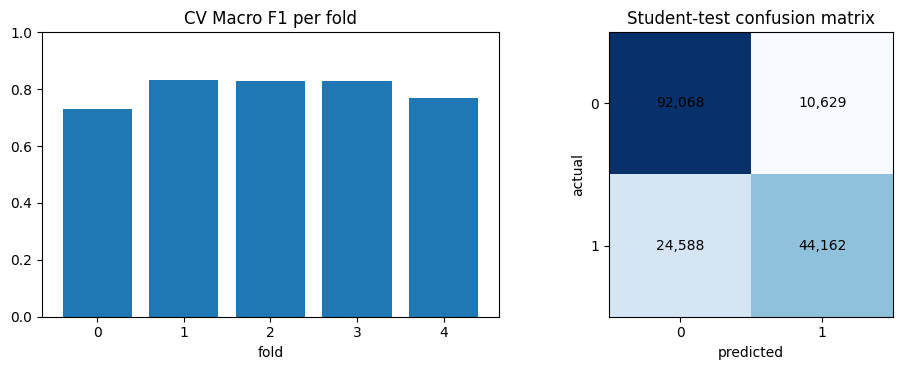

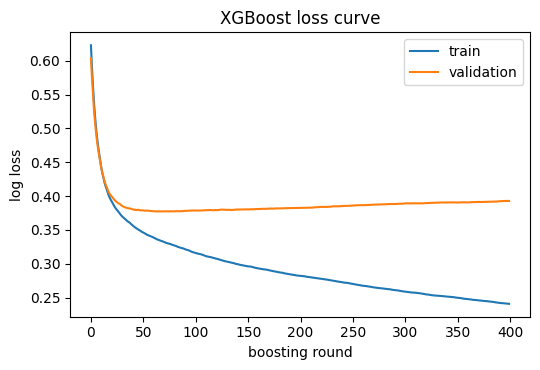

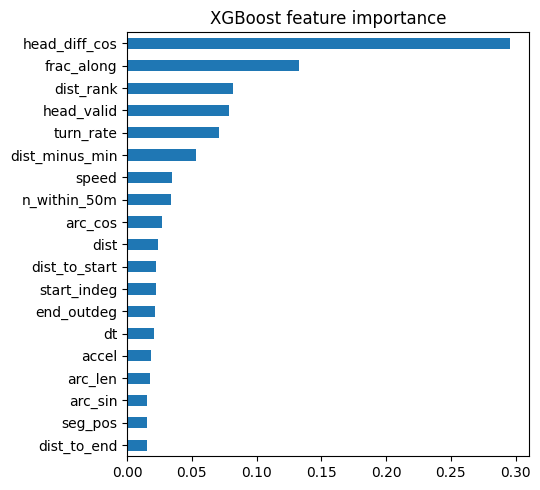

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(cv["fold"].astype(str), cv["macro_f1"]); axes[0].set_title("CV Macro F1 per fold")
axes[0].set_xlabel("fold"); axes[0].set_ylim(0, 1)
axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center")
axes[1].set_title("Student-test confusion matrix"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("actual")
axes[1].set_xticks([0, 1]); axes[1].set_yticks([0, 1])
plt.tight_layout(); plt.savefig(os.path.join(OUT, f"{MODEL_NAME}_plots.png"), dpi=150); plt.show()
plt.figure(figsize=(5.5, 3.8))
plt.plot(curves["train_logloss"], label="train"); plt.plot(curves["val_logloss"], label="validation")
plt.xlabel("boosting round"); plt.ylabel("log loss"); plt.legend(); plt.title("XGBoost loss curve")
plt.tight_layout(); plt.savefig(os.path.join(OUT, f"{MODEL_NAME}_loss_curve.png"), dpi=150); plt.show()

imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(5.5, 5)); imp.plot.barh(); plt.title("XGBoost feature importance")
plt.tight_layout(); plt.savefig(os.path.join(OUT, f"{MODEL_NAME}_feature_importance.png"), dpi=150); plt.show()

## Notes for the report
- XGBoost records a real per-round loss history, so the loss curve is legitimate; it comes from the actual fit.
- Training and validation loss gaps show overfitting, if any; describe only what the curve shows.
- The scaler was fit on `train` only while the CV pool includes `val`; this has no effect on tree models.
- Report only the numbers produced by running this notebook.